#### Observations, baselines, and projection periods

ProFSea supports flexible baseline and projection periods, allowing sea-level observations and projections to be expressed relative to a user-specified reference period. This notebook introduces these concepts and demonstrates how to read the observational datasets provided with ProFSea and compare them with sea-level projections.

---

A baseline period defines the reference level against which sea-level change is reported. More concretely, following the convention used for sea-level projections in IPCC AR5 and AR6, a sea-level change time series $S(t)$ can be expressed relative to a chosen baseline by subtracting its mean over that period,

$S_{\rm rel}(t) = S(t) - \bar{S}_{\rm baseline}$.

This is distinct from the projection period, which defines the time period over which `ProFSea` returns sea-level projections. In `ProFSea` these are specified independently through `baseline_start`, `baseline_end`, `start_yr`, and `end_yr` respectively. 

This is an important distinction when observations and projections are compared. Observational sea-level contributions and climate-model inputs (such as GSAT and zostoga) should use a common basline period in order to produce self-consistent (and physically meaningful) projections. 

In [1]:
# standard imports 

import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import xarray as xr

matplotlib.rcParams['mathtext.fontset'] = 'cm'
matplotlib.rcParams['font.family'] = 'STIXGeneral'

#### Choosing a baseline and projection period in `ProFSea`

Throughout this notebook, we will use the AR5 baseline period of $1986-2005$ and produce projections between $2006-2100$. These will be used in the remainder of the notebook when running global sea-level change projections, and reading observational datasets. 

In [2]:
baseline_start = 1986
baseline_end = 2005

start_yr = 2006
end_yr = 2100

#### Reading observational data

The first step is to import the observational data readers, which can all be found in `profsea.utils`. 

In [3]:
from profsea.utils import (
    read_greenland_obs,
    read_antarctic_obs,
    read_glacier_obs,
    read_landwater_obs,
    read_thermal_expansion_obs,
    read_GMSL_obs # observational timeseries for GMSL, based on tide gauge reconstructions and satellite altimetry
)

These observational timeseries are stored as xarray Datasets and are complete for dates in the range $1980-2023$. We will first read the contribution from Greenland to sea-level rise:

In [4]:
greenland = read_greenland_obs(
    baseline_start=baseline_start,
    baseline_end=baseline_end,
)

greenland

<xarray.Dataset> Size: 2kB
Dimensions:   (time: 53)
Coordinates:
  * time      (time) int64 424B 1971 1972 1973 1974 1975 ... 2020 2021 2022 2023
Data variables:
    sle       (time) float64 424B -0.001932 -0.00207 ... 0.01464 0.01511
    sle_unc   (time) float64 424B 9.927e-05 0.0001925 ... 0.001278 0.001291
    rate      (time) float64 424B -0.1832 -0.1832 -0.1626 ... 0.4584 0.4863
    rate_unc  (time) float64 424B 0.1905 0.1905 0.1857 ... 0.1446 0.1547 0.2054
Attributes:
    baseline_start:  1986
    baseline_end:    2005
    component:       total
    reference:       IMBIE3 (Otosaka et al., 2026)

We now read in the other components, which we store for convenience in an observational dictionary.

In [5]:
antarctica = read_antarctic_obs(
    baseline_start=baseline_start,
    baseline_end=baseline_end
)
glaciers = read_glacier_obs(
    baseline_start=baseline_start,
    baseline_end=baseline_end
)
landwater = read_landwater_obs(
    baseline_start=baseline_start,
    baseline_end=baseline_end
)
thermal_expansion = read_thermal_expansion_obs(
    baseline_start=baseline_start,
    baseline_end=baseline_end
)
gmsl = read_GMSL_obs(
    baseline_start=baseline_start,
    baseline_end=baseline_end
)

observations = {
    "GMSL": (gmsl, "black"),
    "Thermal Expansion": (thermal_expansion, "tab:red"),
    "Glaciers": (glaciers, "tab:brown"),
    "Landwater": (landwater, "tab:green"),
    "Greenland": (greenland, "tab:blue"),
    "Antarctica": (antarctica, "tab:orange"),
}

We can now calcualte the total component contribution to global sea level rise, which we then compare with observed GMSL, estimated in Zheng et al., (2026; Sci. Adv.) from a composite of tide gauge reconstructions and satellite altimetry. 

In [6]:
total_sle = sum(
    ds.sle
    for name, (ds, _) in observations.items()
    if name != "GMSL"
)
total_unc = np.sqrt(
    sum(
        ds.sle_unc**2
        for name, (ds, _) in observations.items()
        if name != "GMSL"
    )
)

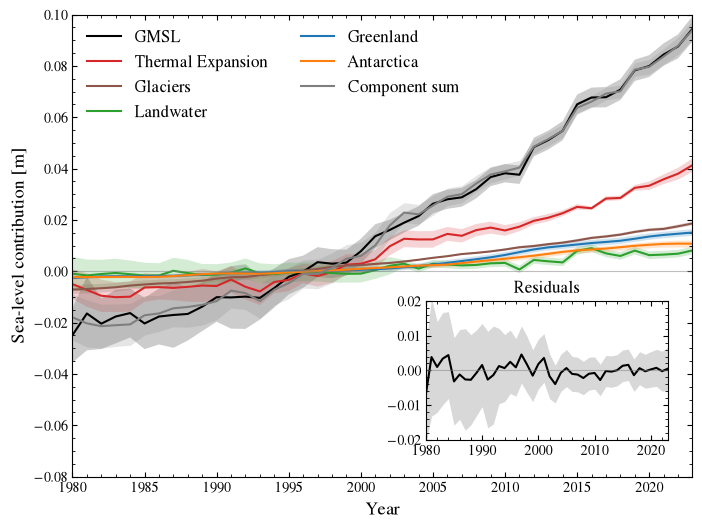

In [7]:
# Residual between observed GMSL and the component sum
gmsl_sle, total_sle, gmsl_unc, total_unc = xr.align(
    gmsl.sle, total_sle, gmsl.sle_unc, total_unc,
    join="inner",
)

# uncertainties in the residual calcualted in quadrature
residual = gmsl_sle - total_sle
residual_unc = np.sqrt(gmsl_unc**2 + total_unc**2)

fig, ax = plt.subplots(figsize=(8, 6))

series = {
    **observations,
    "Component sum": (
        xr.Dataset({"sle": total_sle, "sle_unc": total_unc}),
        "tab:gray",
    ),
}

for label, (ds, color) in series.items():
    ax.plot(ds.time, ds.sle, color=color, label=label)
    ax.fill_between(
        ds.time,
        ds.sle - ds.sle_unc,
        ds.sle + ds.sle_unc,
        color=color, alpha=0.2, lw=0,
    )

axins = ax.inset_axes([0.57, 0.08, 0.39, 0.30])
axins.plot(residual.time, residual, color="black")
axins.fill_between(
    residual.time,
    residual - residual_unc,
    residual + residual_unc,
    color="tab:gray", alpha=0.3, lw=0,
)
axins.set_title("Residuals")

for a in (ax, axins):
    a.axhline(0, color="tab:gray", lw=0.8, alpha=0.5)
    a.set_xlim(1980, 2023)
    a.minorticks_on()
    a.tick_params(which="both", direction="in", top=True, right=True)

ax.set_ylim(-0.08, 0.10)
axins.set_ylim(-0.02, 0.02)

ax.set_xlabel("Year", fontsize=13)
ax.set_ylabel("Sea-level contribution [m]", fontsize=13)

ax.legend(
    loc="upper left", ncol=2,
    frameon=False, fontsize=12
)

plt.show()
plt.close()

#### Ice sheet contributions to sea-level rise

The Greenland and Antarctic observational datasets from IMBIE 3 provide additional detail beyond the total cumulative sea-level contribution. The ice-sheet readers also allow different physical components of mass change to be selected using the `component` argument: this can be "total", "smb" (surface mass balance), or "dyn" (ice dynamics).

For Antarctica, observations can be additionally sub-divided into `region`, allowing the contributions from the East Antarctic Ice Sheet ("eais"), West Antarctic Ice Sheet ("wais"), and Antarctic Peninsula ("peninsula") to be examined separately.

For example, we can read the dynamic contribution from the West Antarctic Ice Sheet using:

In [8]:
wais_dyn = read_antarctic_obs(
    baseline_start=baseline_start,
    baseline_end=baseline_end,
    component="dyn",
    region="wais",
)

wais_dyn

<xarray.Dataset> Size: 2kB
Dimensions:   (time: 45)
Coordinates:
  * time      (time) int64 360B 1979 1980 1981 1982 1983 ... 2020 2021 2022 2023
Data variables:
    sle       (time) float64 360B -0.00172 -0.001529 ... 0.008945 0.009685
    sle_unc   (time) float64 360B 9.757e-05 0.0001486 ... 0.0006701 0.0007078
    rate      (time) float64 360B 0.2311 0.1576 0.08317 ... 0.3782 0.8229 0.6818
    rate_unc  (time) float64 360B 0.1387 0.07299 0.06536 ... 0.1763 0.208 0.2368
Attributes:
    baseline_start:  1986
    baseline_end:    2005
    component:       dyn
    reference:       IMBIE3 (Otosaka et al., 2026)

#### Producing projections with a consistent baseline

We have so far used a common 1986–2005 baseline to examine observed global and component contributions to sea-level change. We will now use the same reference period to construct a global sea-level projection.

---

For this example, we use the AR5 component methods available in ProFSea to produce illustrative AR5-like projections. Note, to produce self-consistent projections it is very important to use the same baseline for the `GSAT` and `zostoga` inputs that are passed to the `Global()` class.


#### Climate-model inputs

For demonstration purposes, this tutorial uses a small subset of preprocessed CMIP5 GSAT and thermosteric sea-level trajectories. These data are provided purely to illustrate the ProFSea workflow (and should not be interpreted as the full ensemble used for AR5 projections!).

The GSAT trajectories provide the temperature anomalies used to drive temperature-dependent components of the projection, while `zostoga` provides the corresponding thermosteric sea-level trajectories. Both quantities are provided here relative to $1986–2005$, matching the baseline used for the observational datasets earlier.

In [9]:
ds = xr.open_dataset("tutorial_data/gsat_zostoga_trajectories.nc")

ds

<xarray.Dataset> Size: 681kB
Dimensions:   (ensemble: 450, time: 94)
Coordinates:
  * ensemble  (ensemble) int64 4kB 0 1 2 3 4 5 6 ... 443 444 445 446 447 448 449
  * time      (time) int64 752B 2006 2007 2008 2009 2010 ... 2096 2097 2098 2099
Data variables:
    gsat      (ensemble, time) float64 338kB ...
    zostoga   (ensemble, time) float64 338kB ...
Attributes:
    scenario:  rcp85
    baseline:  1986-2005

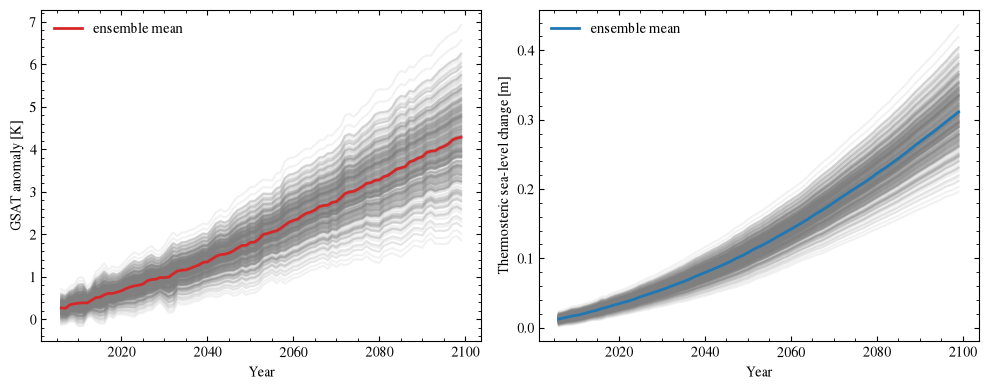

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4))

# GSAT
axs[0].plot(
    ds.time, ds.gsat.T,
    c="tab:gray", alpha=0.1
)
axs[0].plot(
    ds.time, ds.gsat.mean("ensemble"),
    c="tab:red", lw=2,
    label='ensemble mean'
)
axs[0].set(
    xlabel="Year",
    ylabel="GSAT anomaly [K]",
)

# Thermosteric sea level
axs[1].plot(
    ds.time, ds.zostoga.T,
    c="tab:gray", alpha=0.1
)
axs[1].plot(
    ds.time, ds.zostoga.mean("ensemble"),
    c="tab:blue", lw=2,
    label='ensemble mean'
)
axs[1].set(
    xlabel="Year",
    ylabel="Thermosteric sea-level change [m]",
)

for ax in axs:
    ax.minorticks_on()
    ax.tick_params(
        which="both",
        direction="in",
        top=True,
        right=True,
    )
    ax.legend(frameon=False)

plt.tight_layout()
plt.show()
plt.close()

### Configuring the global sea-level model

We first import the sea-level components used in our projection:

In [11]:
from profsea.components.core.global_model import Global
from profsea.components.global_ import (
    AntarcticaDynAR5,
    AntarcticaSMBAR5,
    Glacier,
    GreenlandDynAR5,
    GreenlandSMBAR5,
    LandwaterAR5,
    ThermalExpansion,
)

We instantiate each component and pass them to `Global()` as a dictionary. Thermal expansion differs slightly from the other components because the preprocessed CMIP5 zostoga trajectories are supplied directly when the component is initialised.

In [12]:
global_components = {
    "landwater": LandwaterAR5(),
    "greenlandSMB": GreenlandSMBAR5(),
    "greenlandDyn": GreenlandDynAR5(),
    "expansion": ThermalExpansion(
        ds.zostoga.values,
        OHC_change=False
    ),
    "antarcticaSMB": AntarcticaSMBAR5(),
    "antarcticaDyn": AntarcticaDynAR5(),
    "glacier": Glacier(),
}
global_model = Global(
    components=global_components,
    start_yr=start_yr, 
    end_yr=end_yr,
    baseline_start=baseline_start,
    baseline_end=baseline_end,
    num_members=1000
)

We can now run the simulation and visualise the global projections:

In [13]:
projections = global_model.run(
    T_change=ds.gsat.values, scenario="rcp85", member_seed=42
)
global_model.sum_components(projections)
gmslr = global_model.results["total_gmslr"]

╭──────────────────────────────────── ProFSea Global Run Configuration ─────────────────────────────────────╮
│        Scenario  rcp85                                                                                    │
│      Components  landwater, greenlandSMB, greenlandDyn, expansion, antarcticaSMB, antarcticaDyn, glacier  │
│       Timeframe  2006 -> 2100                                                                             │
│   Ensemble Size  450 inputs × 1000 draws (= 450000)                                                       │
│          Output  Full Distribution (450000 members)                                                       │
│  Compute Engine  Parallel Threading                                                                       │
╰───────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Because the observational records and projections are expressed relative to a consistent $1986–2005$ baseline, their sea-level contributions can now be compared directly over their overlapping period.

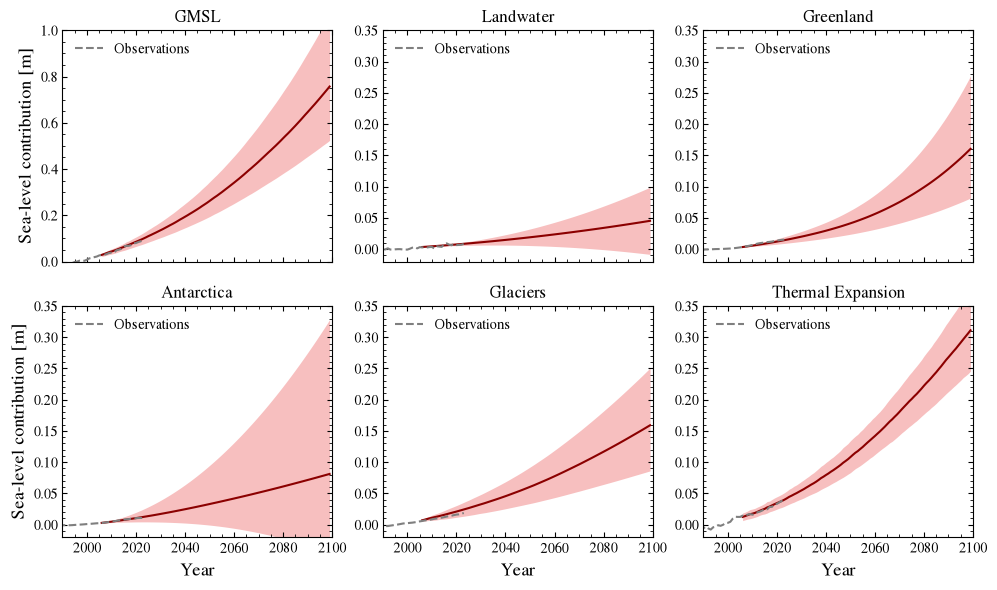

In [14]:
component_projections = {
    "GMSL": gmslr,
    "Landwater": projections["landwater"],
    "Greenland": (
        projections["greenlandSMB"]
        + projections["greenlandDyn"]
    ),
    "Antarctica": (
        projections["antarcticaSMB"]
        + projections["antarcticaDyn"]
    ),
    "Glaciers": projections["glacier"],
    "Thermal Expansion": projections["expansion"],
}

fig, axs = plt.subplots(
    2, 3,
    figsize=(10, 6),
    sharex=True,
)

axs = axs.ravel()

for ax, (label, values) in zip(axs, component_projections.items()):

    lower, upper = np.percentile(values, [5, 95], axis=(0, 1))
    mean = values.mean(axis=(0, 1))

    ax.fill_between(
        ds.time,
        lower,
        upper,
        color="lightcoral",
        alpha=0.5,
        lw=0,
    )
    ax.plot(
        ds.time,
        mean,
        color="darkred",
        lw=1.5,
    )

    if label in observations:
        obs, _ = observations[label]

        ax.plot(
            obs.time, obs.sle, c='tab:gray',
            ls='--', label='Observations'
        )

    ax.set_title(label)
    ax.minorticks_on()
    ax.tick_params(
        which="both",
        direction="in",
        top=True,
        right=True,
    )

    ax.set_xlim(1990, 2100)

    ax.legend(frameon=False, loc='upper left')

for ax in axs[3:]:
    ax.set_xlabel("Year", fontsize=13)
for ax in axs[1:]:
    ax.set_ylim(-0.02, 0.35)

axs[0].set_ylim(0, 1)

axs[0].set_ylabel("Sea-level contribution [m]", fontsize=13)
axs[3].set_ylabel("Sea-level contribution [m]", fontsize=13)

plt.tight_layout()

plt.show()
plt.close()